[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](
https://colab.research.google.com/github/juliopez/Taller-Fundamentos-Data-Science-Python/blob/main/Machine_Learning_2026/03_Notebooks/NB00_Nivelacion_Datos_Machine_Learning.ipynb)

# NB0 — Nivelación: fundamentos prácticos para trabajar con datos en Machine Learning

**Correspondencia: Semana 2**

**Dataset:** `clientes_retail_video_limpieza.csv`


## 1. Cargar librerías


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split


## 2. Cargar el dataset

Suba el archivo **`clientes_retail_video_limpieza.csv`** entregado junto con este notebook.


In [2]:
uploaded = files.upload()

nombre_archivo = list(uploaded.keys())[0]
df = pd.read_csv(nombre_archivo)

print("Archivo cargado:", nombre_archivo)
df.head()


Saving clientes_retail_video_limpieza.csv to clientes_retail_video_limpieza.csv
Archivo cargado: clientes_retail_video_limpieza.csv


,id_cliente,edad,genero,region,canal_preferido,categoria_frecuente,frecuencia_compra,monto_total,satisfaccion
0,1001,56.0,F,Metropolitana,Online,Tecnología,7.0,350309.0,5
1,1002,69.0,F,Metropolitana,Online,Vestuario,7.0,176278.0,1
2,1003,46.0,F,Coquimbo,online,Hogar,6.0,118391.0,5
3,1004,32.0,M,Biobío,Online,Vestuario,8.0,91239.0,5
4,1005,60.0,M,Biobío,Online,Vestuario,3.0,120712.0,2


## 3. Inspeccionar los datos: `head()`, `shape`, `info()` y `describe()`


In [3]:
display(df.head())

print("\nFilas y columnas:", df.shape)

print("\nInformación general:")
df.info()

print("\nResumen descriptivo:")
display(df.describe(include="all"))


,id_cliente,edad,genero,region,canal_preferido,categoria_frecuente,frecuencia_compra,monto_total,satisfaccion
0,1001,56.0,F,Metropolitana,Online,Tecnología,7.0,350309.0,5
1,1002,69.0,F,Metropolitana,Online,Vestuario,7.0,176278.0,1
2,1003,46.0,F,Coquimbo,online,Hogar,6.0,118391.0,5
3,1004,32.0,M,Biobío,Online,Vestuario,8.0,91239.0,5
4,1005,60.0,M,Biobío,Online,Vestuario,3.0,120712.0,2



Filas y columnas: (122, 9)

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122 entries, 0 to 121
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id_cliente           122 non-null    int64  
 1   edad                 118 non-null    float64
 2   genero               122 non-null    object 
 3   region               122 non-null    object 
 4   canal_preferido      122 non-null    object 
 5   categoria_frecuente  122 non-null    object 
 6   frecuencia_compra    122 non-null    float64
 7   monto_total          119 non-null    float64
 8   satisfaccion         122 non-null    int64  
dtypes: float64(3), int64(2), object(4)
memory usage: 8.7+ KB

Resumen descriptivo:


,id_cliente,edad,genero,region,canal_preferido,categoria_frecuente,frecuencia_compra,monto_total,satisfaccion
count,122.000000,118.000000,122,122,122,122,122.000000,119.000000,122.000000
unique,NaN,NaN,3,4,7,6,NaN,NaN,NaN
top,NaN,NaN,F,Coquimbo,Online,Tecnología,NaN,NaN,NaN
freq,NaN,NaN,58,39,70,39,NaN,NaN,NaN
mean,1059.877049,46.050847,NaN,NaN,NaN,NaN,5.081967,186010.848739,2.975410
std,34.884835,17.410503,NaN,NaN,NaN,NaN,2.540873,111915.827884,1.479687
min,1001.000000,15.000000,NaN,NaN,NaN,NaN,-3.000000,27733.000000,1.000000
25%,1030.250000,32.000000,NaN,NaN,NaN,NaN,4.000000,100110.500000,2.000000
50%,1059.500000,43.000000,NaN,NaN,NaN,NaN,5.000000,161956.000000,3.000000
75%,1089.750000,61.000000,NaN,NaN,NaN,NaN,7.000000,251067.500000,4.000000


## 4. Seleccionar filas y columnas

Operaciones básicas que se utilizarán durante todo el semestre:

- seleccionar una columna;
- seleccionar varias columnas;
- usar `loc`;
- usar `iloc`;
- aplicar filtros;
- ordenar resultados;
- revisar categorías;
- resumir información mediante `value_counts()` y `groupby()`.


In [4]:
# Seleccionar una columna
display(df["monto_total"].head())

# Seleccionar varias columnas
display(df[["edad", "monto_total", "canal_preferido"]].head())

# loc: seleccionar por etiquetas/condiciones
display(df.loc[df["monto_total"] > 200000,
               ["id_cliente", "monto_total", "canal_preferido"]].head())

# iloc: seleccionar por posición
display(df.iloc[0:5, 0:4])

# Valores únicos y frecuencias
print("Canales registrados:")
print(df["canal_preferido"].unique())

print("\nFrecuencia por región:")
print(df["region"].value_counts())

# Ordenar
display(df.sort_values("monto_total", ascending=False).head())

# Resumen por grupo
display(
    df.groupby("canal_preferido", dropna=False)["monto_total"]
      .mean()
      .sort_values(ascending=False)
)


,monto_total
0,350309.0
1,176278.0
2,118391.0
3,91239.0
4,120712.0


,edad,monto_total,canal_preferido
0,56.0,350309.0,Online
1,69.0,176278.0,Online
2,46.0,118391.0,online
3,32.0,91239.0,Online
4,60.0,120712.0,Online


,id_cliente,monto_total,canal_preferido
0,1001,350309.0,Online
6,1007,287571.0,Tienda
8,1009,228154.0,Online
9,1010,216016.0,Tienda
10,1011,225718.0,Online


,id_cliente,edad,genero,region
0,1001,56.0,F,Metropolitana
1,1002,69.0,F,Metropolitana
2,1003,46.0,F,Coquimbo
3,1004,32.0,M,Biobío
4,1005,60.0,M,Biobío


Canales registrados:
['Online' ' online ' 'Tienda' 'onl' 'web' 'tienda ' 'presencial']

Frecuencia por región:
region
Coquimbo         39
Metropolitana    34
Biobío           25
Valparaíso       24
Name: count, dtype: int64


,id_cliente,edad,genero,region,canal_preferido,categoria_frecuente,frecuencia_compra,monto_total,satisfaccion
27,1028,38.0,F,Biobío,Online,Tecnología,2.0,556171.0,2
66,1067,24.0,F,Valparaíso,presencial,Tecnología,2.0,510735.0,2
62,1063,19.0,F,Biobío,Online,Deportes,4.0,464194.0,1
12,1013,28.0,F,Coquimbo,Online,Hogar,5.0,436073.0,2
100,1101,33.0,M,Valparaíso,Online,Vestuario,1.0,422125.0,3


,monto_total
canal_preferido,
presencial,510735.000000
web,250883.000000
Tienda,190474.760870
Online,181672.044118
online,118391.000000
tienda,86605.000000
onl,53139.000000


## 5. Identificar tipos de variables

En Machine Learning conviene distinguir, al menos:

- **identificadores**;
- **variables numéricas**;
- **variables categóricas**.

Un identificador como `id_cliente` no debe interpretarse como una característica cuantitativa del cliente.


In [5]:
print(df.dtypes)

variables_numericas = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
variables_categoricas = df.select_dtypes(include=["object"]).columns.tolist()

variables_numericas_analisis = [
    col for col in variables_numericas
    if col != "id_cliente"
]

print("\nVariables numéricas:", variables_numericas)
print("Variables numéricas para análisis:", variables_numericas_analisis)
print("Variables categóricas:", variables_categoricas)


id_cliente               int64
edad                   float64
genero                  object
region                  object
canal_preferido         object
categoria_frecuente     object
frecuencia_compra      float64
monto_total            float64
satisfaccion             int64
dtype: object

Variables numéricas: ['id_cliente', 'edad', 'frecuencia_compra', 'monto_total', 'satisfaccion']
Variables numéricas para análisis: ['edad', 'frecuencia_compra', 'monto_total', 'satisfaccion']
Variables categóricas: ['genero', 'region', 'canal_preferido', 'categoria_frecuente']


## 6. Detectar valores faltantes

Los valores faltantes pueden afectar cálculos, visualizaciones y algoritmos posteriores.


In [6]:
faltantes = df.isnull().sum().sort_values(ascending=False)

print("Valores faltantes por columna:")
print(faltantes)

print("\nTotal de valores faltantes:", int(faltantes.sum()))


Valores faltantes por columna:
edad                   4
monto_total            3
id_cliente             0
region                 0
genero                 0
canal_preferido        0
categoria_frecuente    0
frecuencia_compra      0
satisfaccion           0
dtype: int64

Total de valores faltantes: 7


## 7. Imputar o eliminar valores faltantes

En este ejemplo se utilizará la **mediana** para imputar valores faltantes en `edad` y `monto_total`.

La estrategia adecuada depende del problema, del tipo de variable y de la cantidad de datos faltantes.


In [7]:
df_trabajo = df.copy()

df_trabajo["edad"] = df_trabajo["edad"].fillna(
    df_trabajo["edad"].median()
)

df_trabajo["monto_total"] = df_trabajo["monto_total"].fillna(
    df_trabajo["monto_total"].median()
)

print("Valores faltantes después de imputar:")
print(df_trabajo.isnull().sum())


Valores faltantes después de imputar:
id_cliente             0
edad                   0
genero                 0
region                 0
canal_preferido        0
categoria_frecuente    0
frecuencia_compra      0
monto_total            0
satisfaccion           0
dtype: int64


## 8. Detectar y eliminar duplicados


In [8]:
print("Duplicados detectados:", df_trabajo.duplicated().sum())

df_trabajo = df_trabajo.drop_duplicates().copy()

print("Duplicados después de limpiar:", df_trabajo.duplicated().sum())
print("Dimensión actual:", df_trabajo.shape)


Duplicados detectados: 2
Duplicados después de limpiar: 0
Dimensión actual: (120, 9)


## 9. Corregir categorías inconsistentes

Una misma categoría puede aparecer escrita de distintas formas. Por ejemplo:

`Online`, ` online `, `onl`, `web`.

Antes de analizar o codificar una variable categórica, conviene estandarizar sus valores.


In [9]:
print("Antes:")
print(df_trabajo["canal_preferido"].value_counts(dropna=False))

df_trabajo["canal_preferido"] = (
    df_trabajo["canal_preferido"]
    .str.strip()
    .str.lower()
    .replace({
        "online": "Online",
        "onl": "Online",
        "web": "Online",
        "tienda": "Tienda",
        "presencial": "Tienda"
    })
)

df_trabajo["categoria_frecuente"] = (
    df_trabajo["categoria_frecuente"]
    .str.strip()
    .str.title()
)

print("\nDespués:")
print(df_trabajo["canal_preferido"].value_counts())
print("\nCategorías frecuentes:")
print(df_trabajo["categoria_frecuente"].value_counts())


Antes:
canal_preferido
Online        69
Tienda        46
 online        1
onl            1
web            1
tienda         1
presencial     1
Name: count, dtype: int64

Después:
canal_preferido
Online    72
Tienda    48
Name: count, dtype: int64

Categorías frecuentes:
categoria_frecuente
Tecnología    40
Vestuario     31
Deportes      26
Hogar         23
Name: count, dtype: int64


## 10. Detectar valores fuera de rango

Un valor puede ser numérico y, sin embargo, no ser razonable para el problema.

En este dataset:

- se considerará válida una edad entre **18 y 80 años**;
- `frecuencia_compra` no puede ser negativa.


In [10]:
print("Edades fuera de rango:")
display(
    df_trabajo.loc[
        (df_trabajo["edad"] < 18) | (df_trabajo["edad"] > 80),
        ["id_cliente", "edad"]
    ]
)

print("Frecuencias negativas:")
display(
    df_trabajo.loc[
        df_trabajo["frecuencia_compra"] < 0,
        ["id_cliente", "frecuencia_compra"]
    ]
)

mediana_edad = df_trabajo.loc[
    df_trabajo["edad"].between(18, 80),
    "edad"
].median()

df_trabajo.loc[
    ~df_trabajo["edad"].between(18, 80),
    "edad"
] = mediana_edad

df_trabajo.loc[
    df_trabajo["frecuencia_compra"] < 0,
    "frecuencia_compra"
] = 0

print("Correcciones aplicadas.")


Edades fuera de rango:


,id_cliente,edad
8,1009,15.0
54,1055,96.0


Frecuencias negativas:


,id_cliente,frecuencia_compra
23,1024,-3.0


Correcciones aplicadas.


## 11. Codificar variables categóricas

Muchos algoritmos necesitan entradas numéricas. Una alternativa es **one-hot encoding**, que crea columnas binarias para representar cada categoría.


In [11]:
variables_categoricas = df_trabajo.select_dtypes(
    include=["object"]
).columns.tolist()

df_codificado = pd.get_dummies(
    df_trabajo,
    columns=variables_categoricas,
    drop_first=False,
    dtype=int
)

print("Columnas antes:", df_trabajo.shape[1])
print("Columnas después:", df_codificado.shape[1])

display(df_codificado.head())


Columnas antes: 9
Columnas después: 18


,id_cliente,edad,frecuencia_compra,monto_total,satisfaccion,genero_F,genero_M,genero_No informa,region_Biobío,region_Coquimbo,region_Metropolitana,region_Valparaíso,canal_preferido_Online,canal_preferido_Tienda,categoria_frecuente_Deportes,categoria_frecuente_Hogar,categoria_frecuente_Tecnología,categoria_frecuente_Vestuario
0,1001,56.0,7.0,350309.0,5,1,0,0,0,0,1,0,1,0,0,0,1,0
1,1002,69.0,7.0,176278.0,1,1,0,0,0,0,1,0,1,0,0,0,0,1
2,1003,46.0,6.0,118391.0,5,1,0,0,0,1,0,0,1,0,0,1,0,0
3,1004,32.0,8.0,91239.0,5,0,1,0,1,0,0,0,1,0,0,0,0,1
4,1005,60.0,3.0,120712.0,2,0,1,0,1,0,0,0,1,0,0,0,0,1


## 12. Normalizar y estandarizar

### Normalización
Transforma los valores a un rango común, normalmente **0–1**.

### Estandarización
Transforma una variable para que tenga aproximadamente:

- media = 0;
- desviación estándar = 1.

`id_cliente` se excluye porque es un identificador.


In [12]:
variables_numericas = df_trabajo.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

variables_numericas_analisis = [
    col for col in variables_numericas
    if col != "id_cliente"
]

# Normalización
normalizador = MinMaxScaler()

df_normalizado = df_codificado.copy()
df_normalizado[variables_numericas_analisis] = normalizador.fit_transform(
    df_normalizado[variables_numericas_analisis]
)

# Estandarización
estandarizador = StandardScaler()

df_estandarizado = df_codificado.copy()
df_estandarizado[variables_numericas_analisis] = estandarizador.fit_transform(
    df_estandarizado[variables_numericas_analisis]
)

print("Normalizado:")
display(df_normalizado[variables_numericas_analisis].head())

print("Estandarizado:")
display(df_estandarizado[variables_numericas_analisis].head())


Normalizado:


,edad,frecuencia_compra,monto_total,satisfaccion
0,0.666667,0.583333,0.610433,1.00
1,0.894737,0.583333,0.281102,0.00
2,0.491228,0.500000,0.171558,1.00
3,0.245614,0.666667,0.120177,1.00
4,0.736842,0.250000,0.175951,0.25


Estandarizado:


,edad,frecuencia_compra,monto_total,satisfaccion
0,0.642285,0.784142,1.482349,1.361799
1,1.441300,0.784142,-0.087227,-1.350498
2,0.027658,0.378551,-0.609307,1.361799
3,-0.832819,1.189732,-0.854189,1.361799
4,0.888136,-0.838221,-0.588374,-0.672424


## 13. Visualización básica

Las visualizaciones permiten reconocer distribuciones, diferencias entre grupos y posibles anomalías.


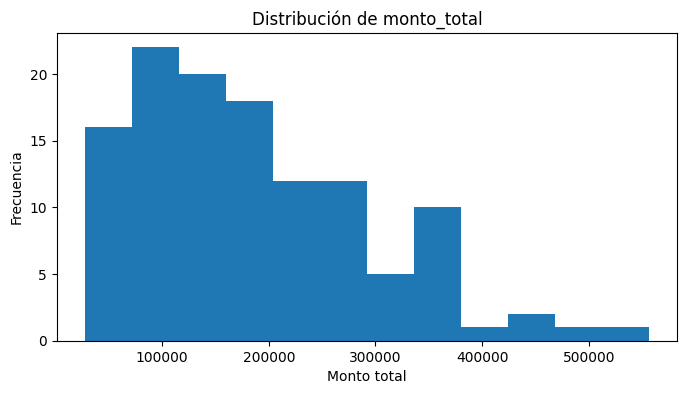

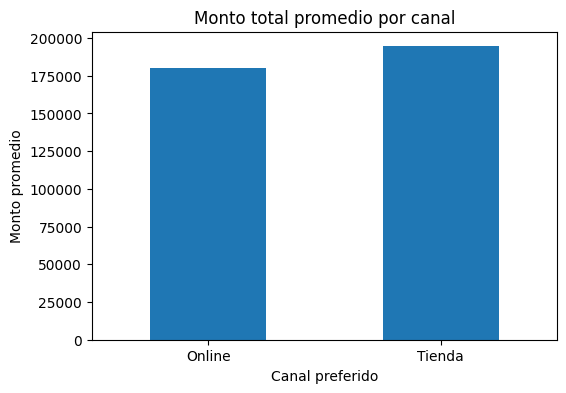

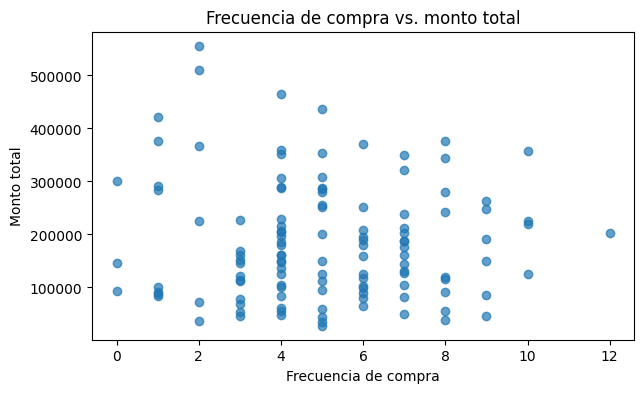

In [13]:
plt.figure(figsize=(8, 4))
plt.hist(df_trabajo["monto_total"].dropna(), bins=12)
plt.title("Distribución de monto_total")
plt.xlabel("Monto total")
plt.ylabel("Frecuencia")
plt.show()

promedio_canal = (
    df_trabajo.groupby("canal_preferido")["monto_total"]
    .mean()
)

plt.figure(figsize=(6, 4))
promedio_canal.plot(kind="bar")
plt.title("Monto total promedio por canal")
plt.xlabel("Canal preferido")
plt.ylabel("Monto promedio")
plt.xticks(rotation=0)
plt.show()

plt.figure(figsize=(7, 4))
plt.scatter(
    df_trabajo["frecuencia_compra"],
    df_trabajo["monto_total"],
    alpha=0.7
)
plt.title("Frecuencia de compra vs. monto total")
plt.xlabel("Frecuencia de compra")
plt.ylabel("Monto total")
plt.show()


## 14. Separar datos en entrenamiento y prueba

Una práctica fundamental en Machine Learning es reservar datos que no participen del entrenamiento.

En este ejemplo se utilizará una división:

- **70% entrenamiento**;
- **30% prueba**.

También se muestra una partición estratificada utilizando `canal_preferido` como referencia pedagógica.


In [14]:
train_df, test_df = train_test_split(
    df_estandarizado,
    test_size=0.30,
    random_state=42
)

print("Entrenamiento:", train_df.shape)
print("Prueba:", test_df.shape)

# Ejemplo de estratificación
train_strat, test_strat = train_test_split(
    df_estandarizado,
    test_size=0.30,
    random_state=42,
    stratify=df_trabajo["canal_preferido"]
)

print("\nDistribución original:")
print(df_trabajo["canal_preferido"].value_counts(normalize=True))

print("\nDistribución entrenamiento estratificado:")
print(
    df_trabajo.loc[train_strat.index, "canal_preferido"]
    .value_counts(normalize=True)
)

print("\nDistribución prueba estratificada:")
print(
    df_trabajo.loc[test_strat.index, "canal_preferido"]
    .value_counts(normalize=True)
)


Entrenamiento: (84, 18)
Prueba: (36, 18)

Distribución original:
canal_preferido
Online    0.6
Tienda    0.4
Name: proportion, dtype: float64

Distribución entrenamiento estratificado:
canal_preferido
Online    0.595238
Tienda    0.404762
Name: proportion, dtype: float64

Distribución prueba estratificada:
canal_preferido
Online    0.611111
Tienda    0.388889
Name: proportion, dtype: float64


## 15. Exportar el resultado

Al finalizar una preparación de datos conviene guardar el resultado y mantener trazabilidad de las transformaciones realizadas.


In [15]:
# Validación final
print("Valores faltantes:", df_estandarizado.isnull().sum().sum())
print("Duplicados:", df_estandarizado.duplicated().sum())
print("Dimensión final:", df_estandarizado.shape)

# Exportar
archivo_salida = "clientes_retail_preparado_NB0.csv"
df_estandarizado.to_csv(archivo_salida, index=False)

print("\nArchivo generado:", archivo_salida)

# Descargar desde Colab
files.download(archivo_salida)


Valores faltantes: 0
Duplicados: 0
Dimensión final: (120, 18)

Archivo generado: clientes_retail_preparado_NB0.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Checklist de nivelación

Al finalizar NB0, el estudiante debería ser capaz de:

- cargar un CSV en Google Colab;
- inspeccionar un DataFrame;
- seleccionar y filtrar datos;
- distinguir variables numéricas, categóricas e identificadores;
- detectar e imputar valores faltantes;
- detectar y eliminar duplicados;
- corregir categorías inconsistentes;
- identificar valores fuera de rango;
- aplicar one-hot encoding;
- normalizar y estandarizar variables;
- realizar visualizaciones básicas;
- separar datos en entrenamiento y prueba;
- exportar un dataset preparado.
